# RotaLivre — Modelo de Agrupamento de Barreiras Urbanas

Este notebook desenvolve um modelo de Machine Learning não supervisionado para identificar agrupamentos geográficos de locais urbanos.

O algoritmo utilizado será o KMeans, que agrupa pontos com características geográficas semelhantes utilizando latitude e longitude.

O objetivo é identificar regiões que concentram locais mapeados e apoiar futuras análises de acessibilidade urbana.

**Métricas utilizadas:**
- Inércia: mede a soma das distâncias quadráticas dos pontos até seus respectivos centros.
- Silhouette Score: avalia o quanto os pontos estão próximos de seu próprio grupo e distantes dos demais.

**Importante:** os dados geográficos desta etapa são sintéticos e não representam locais reais.

In [1]:
# Manipulação dos dados
import pandas as pd
import numpy as np

# Algoritmo de agrupamento e métricas
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Exportação do modelo
import joblib
import json
from pathlib import Path

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
# Identifica a pasta principal do projeto
raiz_projeto = Path.cwd()

# Se o notebook estiver dentro da pasta notebooks,
# volta um nível para chegar à raiz do projeto
if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

# Localiza o CSV
caminho_csv = raiz_projeto / "dados" / "locais_acessibilidade.csv"

if not caminho_csv.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_csv}")

# Carrega a base
df = pd.read_csv(caminho_csv)

print("Base carregada com sucesso!")
print(f"Registros encontrados: {len(df)}")

df.head()

Base carregada com sucesso!
Registros encontrados: 600


,id_local,tipo_local,largura_calcada_m,inclinacao_graus,rampa,piso_tatil,piso_regular,sinalizacao_acessivel,quantidade_relatos,usuarios_distintos,nota_acessibilidade,situacao_acessibilidade,latitude,longitude,origem_dados
0,1,ESTABELECIMENTO,2.40,13.18,0,0,0,1,2,2,52,PARCIAL,-23.529384,-46.654258,SINTETICO_SIMULADO
1,2,ELEVADOR,0.49,17.46,1,1,1,1,15,11,52,PARCIAL,-23.585950,-46.609499,SINTETICO_SIMULADO
2,3,CALCADA,1.53,7.20,1,1,1,1,14,13,86,ACESSIVEL,-23.575230,-46.618999,SINTETICO_SIMULADO
3,4,CALCADA,0.55,10.94,0,0,0,1,3,0,35,INACESSIVEL,-23.576061,-46.613433,SINTETICO_SIMULADO
4,5,RAMPA,1.85,7.92,0,1,0,1,14,2,65,PARCIAL,-23.532210,-46.623183,SINTETICO_SIMULADO


In [3]:
# Confere se as colunas geográficas estão disponíveis
colunas_geograficas = ["latitude", "longitude"]

for coluna in colunas_geograficas:
    if coluna not in df.columns:
        raise ValueError(f"Coluna obrigatória ausente: {coluna}")

# Remove registros sem coordenadas válidas
dados_geo = df.dropna(
    subset=colunas_geograficas
).copy()

print("Registros com coordenadas válidas:", len(dados_geo))
print("\nResumo das coordenadas:")
display(dados_geo[colunas_geograficas].describe())

print("\nOrigem dos dados:")
print(dados_geo["origem_dados"].value_counts())

Registros com coordenadas válidas: 600

Resumo das coordenadas:


,latitude,longitude
count,600.000000,600.000000
mean,-23.546923,-46.630827
std,0.020593,0.020897
min,-23.586089,-46.669957
25%,-23.572560,-46.655913
50%,-23.535874,-46.619405
75%,-23.530954,-46.614334
max,-23.516516,-46.602774



Origem dos dados:
origem_dados
SINTETICO_SIMULADO    600
Name: count, dtype: int64


In [4]:
# Calcula um ponto de referência para converter latitude e longitude
# em distâncias aproximadas em quilômetros.
latitude_referencia = dados_geo["latitude"].mean()
longitude_referencia = dados_geo["longitude"].mean()

# Um grau de latitude corresponde aproximadamente a 111,32 km.
# Para longitude, corrigimos a distância usando o cosseno da latitude.
fator_longitude = 111.32 * np.cos(
    np.radians(latitude_referencia)
)

# Cria coordenadas aproximadas em quilômetros.
# Isso facilita a interpretação das distâncias pelo KMeans.
dados_geo["x_km"] = (
    dados_geo["longitude"] - longitude_referencia
) * fator_longitude

dados_geo["y_km"] = (
    dados_geo["latitude"] - latitude_referencia
) * 111.32

# Seleciona as duas variáveis utilizadas no agrupamento.
X_geo = dados_geo[["x_km", "y_km"]].copy()

print("Coordenadas preparadas!")
display(X_geo.head())

Coordenadas preparadas!


,x_km,y_km
0,-2.391152,1.952481
1,2.176537,-4.344446
2,1.207055,-3.151096
3,1.775070,-3.243603
4,0.780075,1.637891


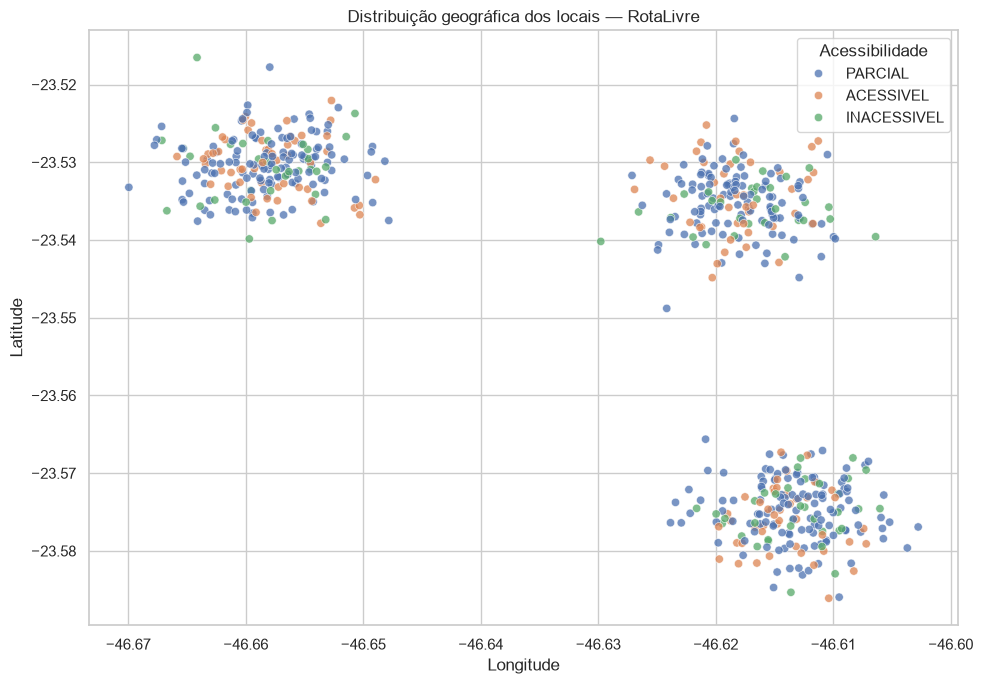

In [5]:
# Mostra a distribuição dos locais antes do agrupamento.
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=dados_geo,
    x="longitude",
    y="latitude",
    hue="situacao_acessibilidade",
    alpha=0.75
)

plt.title("Distribuição geográfica dos locais — RotaLivre")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Acessibilidade")
plt.tight_layout()
plt.show()

In [6]:
# Testa diferentes quantidades de clusters.
# O KMeans precisa de pelo menos dois grupos para calcular o Silhouette.
quantidades_clusters = range(2, 9)

resultados = []

for quantidade in quantidades_clusters:

    # Cria e treina o KMeans para a quantidade atual de grupos.
    kmeans_teste = KMeans(
        n_clusters=quantidade,
        random_state=42,
        n_init=20
    )

    grupos_teste = kmeans_teste.fit_predict(X_geo)

    # Calcula as métricas de avaliação.
    inercia = kmeans_teste.inertia_
    silhouette = silhouette_score(X_geo, grupos_teste)

    resultados.append({
        "quantidade_clusters": quantidade,
        "inercia": inercia,
        "silhouette": silhouette
    })

# Organiza os resultados em uma tabela.
resultados_clusters = pd.DataFrame(resultados)

display(resultados_clusters)

,quantidade_clusters,inercia,silhouette
0,2,1899.266213,0.653922
1,3,216.444888,0.819715
2,4,189.566277,0.640773
3,5,162.997366,0.472627
4,6,139.149487,0.332492
5,7,122.828649,0.342151
6,8,109.048087,0.342902


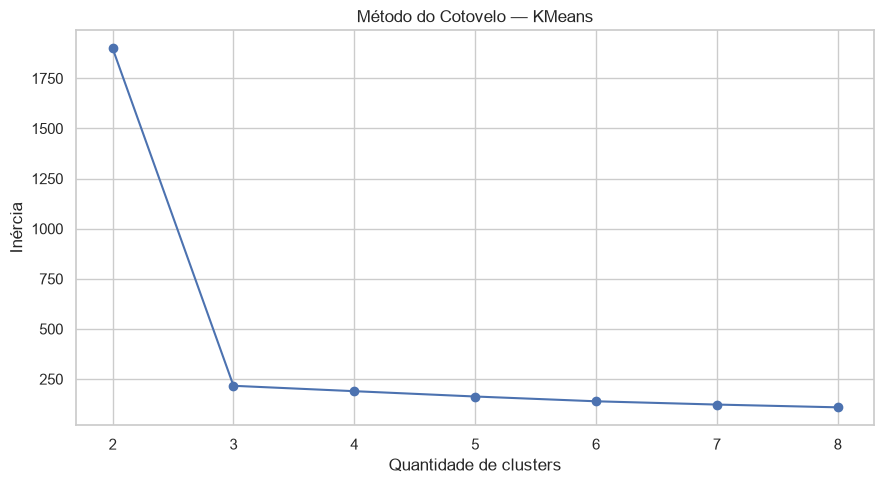

In [7]:
# O gráfico de inércia ajuda a observar em qual ponto
# adicionar novos grupos passa a trazer ganhos menores.
plt.figure(figsize=(9, 5))

plt.plot(
    resultados_clusters["quantidade_clusters"],
    resultados_clusters["inercia"],
    marker="o"
)

plt.title("Método do Cotovelo — KMeans")
plt.xlabel("Quantidade de clusters")
plt.ylabel("Inércia")
plt.xticks(list(quantidades_clusters))
plt.tight_layout()
plt.show()

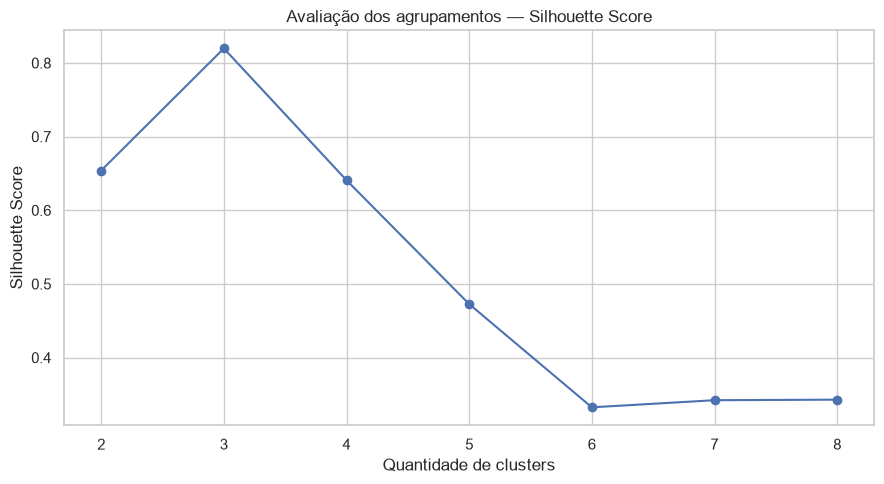

Quantidade selecionada de clusters: 3
Silhouette Score: 0.8197


In [8]:
# Quanto maior o Silhouette Score, melhor a separação
# dos grupos, considerando essa métrica.
plt.figure(figsize=(9, 5))

plt.plot(
    resultados_clusters["quantidade_clusters"],
    resultados_clusters["silhouette"],
    marker="o"
)

plt.title("Avaliação dos agrupamentos — Silhouette Score")
plt.xlabel("Quantidade de clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(quantidades_clusters))
plt.tight_layout()
plt.show()

# Seleciona a quantidade de grupos com o maior Silhouette Score.
melhor_resultado = resultados_clusters.loc[
    resultados_clusters["silhouette"].idxmax()
]

melhor_k = int(melhor_resultado["quantidade_clusters"])

print(f"Quantidade selecionada de clusters: {melhor_k}")
print(
    "Silhouette Score:",
    round(melhor_resultado["silhouette"], 4)
)

In [9]:
# Cria o modelo final utilizando a quantidade de grupos
# selecionada pela avaliação do Silhouette Score.
modelo_kmeans = KMeans(
    n_clusters=melhor_k,
    random_state=42,
    n_init=20
)

# Treina o modelo e atribui um grupo para cada local.
dados_geo["cluster"] = modelo_kmeans.fit_predict(X_geo)

print("Modelo KMeans treinado com sucesso!")
print(f"Quantidade de grupos identificados: {melhor_k}")

print("\nQuantidade de locais por grupo:")
print(dados_geo["cluster"].value_counts().sort_index())

Modelo KMeans treinado com sucesso!
Quantidade de grupos identificados: 3

Quantidade de locais por grupo:
cluster
0    183
1    215
2    202
Name: count, dtype: int64


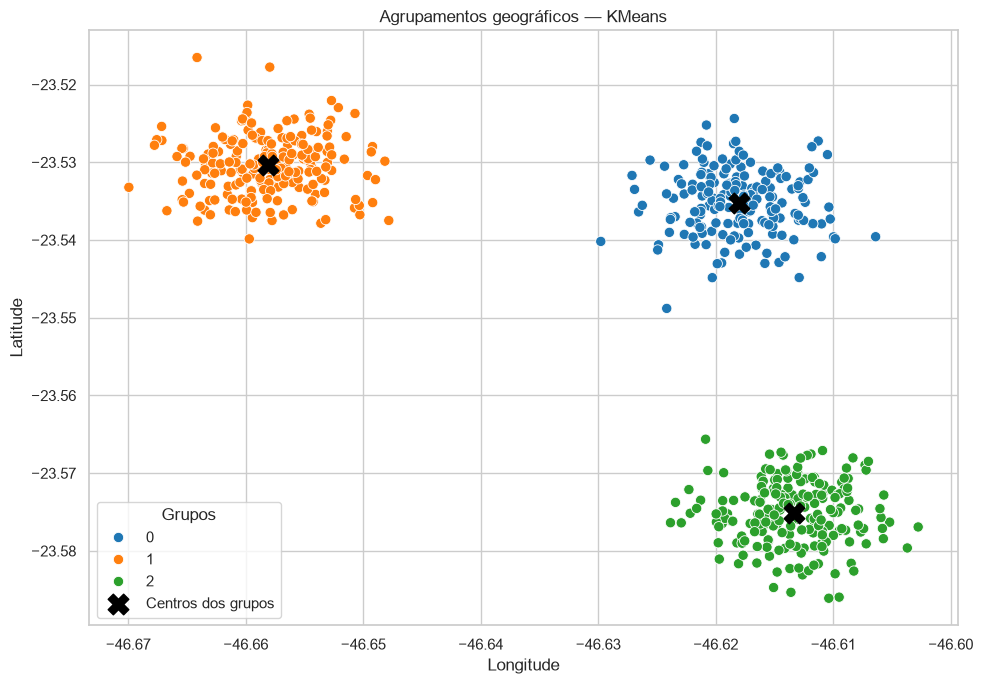

In [10]:
# Exibe os pontos coloridos de acordo com o grupo identificado.
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=dados_geo,
    x="longitude",
    y="latitude",
    hue="cluster",
    palette="tab10",
    s=55
)

# Converte os centros dos grupos de quilômetros para coordenadas geográficas.
centros = modelo_kmeans.cluster_centers_

centros_longitude = (
    centros[:, 0] / fator_longitude
) + longitude_referencia

centros_latitude = (
    centros[:, 1] / 111.32
) + latitude_referencia

plt.scatter(
    centros_longitude,
    centros_latitude,
    marker="X",
    s=220,
    color="black",
    label="Centros dos grupos"
)

plt.title("Agrupamentos geográficos — KMeans")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Grupos")
plt.tight_layout()
plt.show()

In [11]:
# Relaciona os grupos geográficos com as classificações de acessibilidade.
resumo_clusters = dados_geo.groupby("cluster").agg(
    quantidade_locais=("id_local", "count"),
    largura_media=("largura_calcada_m", "mean"),
    inclinacao_media=("inclinacao_graus", "mean"),
    nota_media=("nota_acessibilidade", "mean")
).round(2)

print("Resumo dos grupos identificados:")
display(resumo_clusters)

# Mostra a distribuição das classificações em cada grupo.
distribuicao_classes = pd.crosstab(
    dados_geo["cluster"],
    dados_geo["situacao_acessibilidade"]
)

print("\nClassificações por grupo:")
display(distribuicao_classes)

Resumo dos grupos identificados:


,quantidade_locais,largura_media,inclinacao_media,nota_media
cluster,,,,
0,183,1.48,8.75,57.80
1,215,1.49,9.29,58.13
2,202,1.43,8.82,55.51



Classificações por grupo:


situacao_acessibilidade,ACESSIVEL,INACESSIVEL,PARCIAL
cluster,,,
0,42,30,111
1,52,32,131
2,44,35,123


In [12]:
# Cria a pasta de modelos caso ainda não exista.
pasta_modelos = raiz_projeto / "modelos"
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Caminho do modelo exportado.
caminho_modelo = pasta_modelos / "modelo_agrupamento.joblib"

# Salva o modelo e as informações necessárias para interpretar
# futuras coordenadas usando a mesma referência geográfica.
pacote_modelo = {
    "modelo": modelo_kmeans,
    "latitude_referencia": float(latitude_referencia),
    "longitude_referencia": float(longitude_referencia),
    "fator_longitude": float(fator_longitude),
    "fator_latitude": 111.32
}

joblib.dump(pacote_modelo, caminho_modelo)

# Salva os metadados do experimento.
metadados = {
    "nome": "Modelo de Agrupamento RotaLivre",
    "algoritmo": "KMeans",
    "variaveis": ["latitude", "longitude"],
    "quantidade_clusters": melhor_k,
    "inercia": float(modelo_kmeans.inertia_),
    "silhouette_score": float(
        silhouette_score(X_geo, dados_geo["cluster"])
    ),
    "quantidade_registros": int(len(dados_geo)),
    "origem_dados": "SINTETICO_SIMULADO",
    "observacao": (
        "Agrupamentos experimentais com coordenadas sintéticas. "
        "Nao representam hotspots reais."
    )
}

caminho_metadados = pasta_modelos / "metadata_agrupamento.json"

with open(caminho_metadados, "w", encoding="utf-8") as arquivo:
    json.dump(metadados, arquivo, indent=4, ensure_ascii=False)

# Exporta também uma cópia dos dados com os grupos atribuídos.
caminho_resultados = (
    raiz_projeto / "dados" / "locais_com_clusters.csv"
)

dados_geo.to_csv(
    caminho_resultados,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos exportados com sucesso!")
print(f"Modelo: {caminho_modelo}")
print(f"Metadados: {caminho_metadados}")
print(f"Dados agrupados: {caminho_resultados}")

Arquivos exportados com sucesso!
Modelo: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\modelos\modelo_agrupamento.joblib
Metadados: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\modelos\metadata_agrupamento.json
Dados agrupados: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\dados\locais_com_clusters.csv


## Conclusão

Neste notebook foi desenvolvido um modelo de agrupamento geográfico utilizando KMeans.

O processo incluiu:

- Preparação das coordenadas geográficas.
- Conversão aproximada das coordenadas para quilômetros.
- Teste de diferentes quantidades de grupos.
- Avaliação por inércia e Silhouette Score.
- Treinamento do modelo final.
- Visualização dos agrupamentos e centros.
- Análise das características dos grupos.
- Exportação do modelo e dos resultados.

**Limitação:** os dados utilizados são sintéticos. Os agrupamentos não representam regiões reais com concentração comprovada de barreiras de acessibilidade.

Quando os dados reais estiverem disponíveis, será necessário repetir o experimento com as coordenadas oficiais dos locais.